# Лабораторна робота №7: Інкрементальна обробка та відстеження змін у даних

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Stanislavwx/Methods-and-Technologies-of-Data-Engineering/blob/main/Lab7/Lab7_DEMT.ipynb)

**Дисципліна:** Методи та технології інженерії даних  
**Студент:** Чепара Станіслав (група ФеП-32)  
**Викладач:** асистент кафедри системного проєктування Фостяк Маркіян Романович  
**Навчальний заклад:** Львівський національний університет імені Івана Франка  

---

## 🎯 Мета роботи
Набути практичних навичок інкрементальної обробки даних: поділу даних на часові пакети, послідовної обробки нових порцій даних, оновлення результуючої таблиці, відстеження змін та перевірки правильності інкрементальної обробки шляхом порівняння з результатами повної обробки набору даних.

In [1]:
import os
import time
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування стилю для графіків
sns.set_theme(style="whitegrid", font="DejaVu Sans")
os.makedirs("plots", exist_ok=True)
print("Бібліотеки успішно імпортовано!")

Бібліотеки успішно імпортовано!


## 1. Первинна підготовка даних

- Завантаження початкового набору даних `data_student_rfm1.csv`.
- Визначення кількості записів, ознак, типів даних, кількості унікальних покупців та транзакцій.
- Перетворення `purchase_date` у формат `datetime`.
- Перевірка наявності пропущених значень та дублікатів.
- Розрахунок вартості покупки: `amount = quantity * unit_price`.

In [2]:
# 1. Завантаження датасету
df_raw = pd.read_csv("data_student_rfm1.csv")
if "Unnamed: 0" in df_raw.columns:
    df_raw = df_raw.drop(columns=["Unnamed: 0"])

print(f"Розмірність вхідного набору: {df_raw.shape[0]} рядків, {df_raw.shape[1]} колонок")
print("\nТипи даних початкових ознак:")
print(df_raw.dtypes)

print(f"\nКількість унікальних інвойсів (транзакцій): {df_raw['InvoiceNo'].nunique()}")
print(f"Кількість унікальних покупців (включно з NaN): {df_raw['CustomerID'].nunique(dropna=False)}")
print(f"Кількість унікальних валідних покупців: {df_raw['CustomerID'].nunique(dropna=True)}")

print("\nПропущені значення за стовпцями:")
print(df_raw.isnull().sum())

# Очищення від транзакцій без CustomerID
df_clean = df_raw.dropna(subset=["CustomerID"]).copy()

# Перевірка та усунення дублікатів
dup_count = df_clean.duplicated().sum()
print(f"\nВиявлено повних дублікатів рядків: {dup_count}")
if dup_count > 0:
    df_clean = df_clean.drop_duplicates().copy()

# Приведення типів даних та створення цільових полів
df_clean["customer_id"] = df_clean["CustomerID"].astype(int)
df_clean["purchase_date"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["quantity"] = df_clean["Quantity"].astype(int)
df_clean["unit_price"] = df_clean["UnitPrice"].astype(float)
df_clean["amount"] = df_clean["quantity"] * df_clean["unit_price"]

print(f"\nРозмір очищеного набору: {df_clean.shape[0]} транзакцій, {df_clean['customer_id'].nunique()} унікальних клієнтів")
print(f"Часовий діапазон: {df_clean['purchase_date'].min()} — {df_clean['purchase_date'].max()}")
df_clean[["customer_id", "purchase_date", "quantity", "unit_price", "amount"]].head()

Розмірність вхідного набору: 75365 рядків, 8 колонок

Типи даних початкових ознак:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

Кількість унікальних інвойсів (транзакцій): 16571
Кількість унікальних покупців (включно з NaN): 3993
Кількість унікальних валідних покупців: 3992

Пропущені значення за стовпцями:
InvoiceNo          0
StockCode          0
Description      208
Quantity           0
InvoiceDate        0
UnitPrice          0
CustomerID     18538
Country            0
dtype: int64

Виявлено повних дублікатів рядків: 101



Розмір очищеного набору: 56726 транзакцій, 3992 унікальних клієнтів
Часовий діапазон: 2010-12-01 08:34:00 — 2011-12-09 12:50:00


,customer_id,purchase_date,quantity,unit_price,amount
0,17288,2011-11-27 13:29:00,1,2.10,2.10
1,16511,2011-11-18 10:41:00,1,5.95,5.95
2,17153,2011-11-15 13:42:00,10,2.08,20.80
3,15653,2011-08-16 09:50:00,12,0.85,10.20
4,15344,2011-12-09 10:45:00,2,8.25,16.50


## 2. Формування часових пакетів даних

Відсортувати початковий набір за `purchase_date` та розділити його на три послідовні часові періоди:
- `transactions_period_1.csv`
- `transactions_period_2.csv`
- `transactions_period_3.csv`

Вимога: періоди не повинні перетинатися за датами.

In [3]:
# Сортування за часом покупки
df_sorted = df_clean.sort_values("purchase_date").reset_index(drop=True)

# Поділ на 3 часові інтервали однакової тривалості
min_date = df_sorted["purchase_date"].min()
max_date = df_sorted["purchase_date"].max()
delta = (max_date - min_date) / 3

t1 = min_date + delta
t2 = min_date + 2 * delta

p1 = df_sorted[df_sorted["purchase_date"] < t1].copy()
p2 = df_sorted[(df_sorted["purchase_date"] >= t1) & (df_sorted["purchase_date"] < t2)].copy()
p3 = df_sorted[df_sorted["purchase_date"] >= t2].copy()

# Збереження часових пакетів у файли
p1.to_csv("transactions_period_1.csv", index=False)
p2.to_csv("transactions_period_2.csv", index=False)
p3.to_csv("transactions_period_3.csv", index=False)

print(f"Пакет 1: {len(p1)} транзакцій, діапазон {p1['purchase_date'].min()} — {p1['purchase_date'].max()}")
print(f"Пакет 2: {len(p2)} транзакцій, діапазон {p2['purchase_date'].min()} — {p2['purchase_date'].max()}")
print(f"Пакет 3: {len(p3)} транзакцій, діапазон {p3['purchase_date'].min()} — {p3['purchase_date'].max()}")

# Контроль відсутності часових перетинів
assert p1["purchase_date"].max() < p2["purchase_date"].min()
assert p2["purchase_date"].max() < p3["purchase_date"].min()
print("\nКонтроль пройдено: періоди строго послідовні та не перетинаються за датами!")

Пакет 1: 13752 транзакцій, діапазон 2010-12-01 08:34:00 — 2011-04-04 16:36:00
Пакет 2: 15688 транзакцій, діапазон 2011-04-05 08:25:00 — 2011-08-05 17:43:00
Пакет 3: 27286 транзакцій, діапазон 2011-08-07 10:24:00 — 2011-12-09 12:50:00

Контроль пройдено: періоди строго послідовні та не перетинаються за датами!


## 3–6. Початкове завантаження (Initial Load), інкрементальна обробка та логування

- **Initial Load (Період 1):** формування початкового стану `customers_current.csv`.
- **Інкрементальна обробка (Періоди 2 і 3):** ізольоване читання пакетів, розділення клієнтів на нових (`INSERT`) та існуючих (`UPDATE`).
- **Журнал обробки:** протоколювання стану в `processing.log`.

In [4]:
def aggregate_batch(batch_df):
    """Розрахунок зведених метрик клієнтів для окремого пакета транзакцій."""
    return batch_df.groupby("customer_id").agg(
        number_of_purchases=("quantity", "count"),
        total_quantity=("quantity", "sum"),
        total_spent=("amount", "sum"),
        last_purchase_date=("purchase_date", "max")
    ).reset_index()

def write_log(period_num, filename, b_df, new_count, updated_count, total_count, log_file="processing.log"):
    """Запис аудиторської інформації в processing.log."""
    mode = "w" if period_num == 1 else "a"
    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    entry = (
        f"Period {period_num}\n"
        f"File: {filename}\n"
        f"Date range: {b_df['purchase_date'].min()} - {b_df['purchase_date'].max()}\n"
        f"Transactions processed: {len(b_df)}\n"
        f"Customers in batch: {b_df['customer_id'].nunique()}\n"
        f"New customers: {new_count}\n"
        f"Updated customers: {updated_count}\n"
        f"Customers after processing: {total_count}\n"
        f"Execution time: {timestamp}\n"
        f"Status: SUCCESS\n"
        f"{'-' * 50}\n"
    )
    with open(log_file, mode, encoding="utf-8") as f:
        f.write(entry)

In [5]:
batches = [
    ("Period 1", "transactions_period_1.csv"),
    ("Period 2", "transactions_period_2.csv"),
    ("Period 3", "transactions_period_3.csv"),
]

customers_current = None
summary_stats = []

for idx, (p_name, filename) in enumerate(batches, start=1):
    # Зчитуємо виключно черговий пакет даних
    batch_data = pd.read_csv(filename)
    batch_data["purchase_date"] = pd.to_datetime(batch_data["purchase_date"])
    batch_agg = aggregate_batch(batch_data).set_index("customer_id")
    
    if idx == 1:
        # Initial Load: збереження стану 1
        customers_current = batch_agg.copy()
        new_count = len(customers_current)
        updated_count = 0
        print(f"[{p_name}] Initial Load виконано: додано {new_count} нових клієнтів.")
    else:
        # Incremental Load: INSERT / UPDATE
        cur_ids = set(customers_current.index)
        b_ids = set(batch_agg.index)
        
        new_ids = list(b_ids - cur_ids)
        common_ids = list(b_ids & cur_ids)
        
        # UPDATE для існуючих клієнтів
        if common_ids:
            customers_current.loc[common_ids, "number_of_purchases"] += batch_agg.loc[common_ids, "number_of_purchases"]
            customers_current.loc[common_ids, "total_quantity"] += batch_agg.loc[common_ids, "total_quantity"]
            customers_current.loc[common_ids, "total_spent"] += batch_agg.loc[common_ids, "total_spent"]
            customers_current.loc[common_ids, "last_purchase_date"] = np.maximum(
                pd.to_datetime(customers_current.loc[common_ids, "last_purchase_date"]),
                pd.to_datetime(batch_agg.loc[common_ids, "last_purchase_date"])
            )
        
        # INSERT для нових клієнтів
        if new_ids:
            customers_current = pd.concat([customers_current, batch_agg.loc[new_ids]])
            
        new_count = len(new_ids)
        updated_count = len(common_ids)
        print(f"[{p_name}] Інкрементальне оновлення: {new_count} нових (INSERT), {updated_count} оновлених (UPDATE).")
        
    total_cust = len(customers_current)
    customers_current.sort_index().reset_index().to_csv("customers_current.csv", index=False)
    write_log(idx, filename, batch_data, new_count, updated_count, total_cust)
    
    summary_stats.append({
        "Період": p_name,
        "Файл": filename,
        "Транзакцій": len(batch_data),
        "Клієнтів у пакеті": batch_data["customer_id"].nunique(),
        "Нових покупців": new_count,
        "Оновлено покупців": updated_count,
        "Покупців після обробки": total_cust
    })

customers_incremental = customers_current.sort_index().reset_index()
customers_incremental.to_csv("customers_incremental.csv", index=False)
summary_df = pd.DataFrame(summary_stats)

[Period 1] Initial Load виконано: додано 1917 нових клієнтів.
[Period 2] Інкрементальне оновлення: 957 нових (INSERT), 1137 оновлених (UPDATE).
[Period 3] Інкрементальне оновлення: 1118 нових (INSERT), 1726 оновлених (UPDATE).


In [6]:
# Перегляд вмісту processing.log
with open("processing.log", "r", encoding="utf-8") as f:
    print(f.read())

Period 1
File: transactions_period_1.csv
Date range: 2010-12-01 08:34:00 - 2011-04-04 16:36:00
Transactions processed: 13752
Customers in batch: 1917
New customers: 1917
Updated customers: 0
Customers after processing: 1917
Execution time: 2026-11-09 12:44:30
Status: SUCCESS
--------------------------------------------------
Period 2
File: transactions_period_2.csv
Date range: 2011-04-05 08:25:00 - 2011-08-05 17:43:00
Transactions processed: 15688
Customers in batch: 2094
New customers: 957
Updated customers: 1137
Customers after processing: 2874
Execution time: 2026-11-09 12:44:30
Status: SUCCESS
--------------------------------------------------
Period 3
File: transactions_period_3.csv
Date range: 2011-08-07 10:24:00 - 2011-12-09 12:50:00
Transactions processed: 27286
Customers in batch: 2844
New customers: 1118
Updated customers: 1726
Customers after processing: 3992
Execution time: 2026-11-09 12:44:30
Status: SUCCESS
--------------------------------------------------



## 7. Контрольна повна обробка та верифікація результатів

Виконати контрольну повну обробку початкового набору даних без поділу на періоди (`customers_full`), та перевірити 100% збіг із результатом інкрементальної обробки (`customers_incremental`).

In [7]:
# Повна контрольна обробка всього набору
customers_full = aggregate_batch(df_clean).sort_values("customer_id").reset_index(drop=True)
customers_full.to_csv("customers_full.csv", index=False)

customers_inc = customers_incremental.sort_values("customer_id").reset_index(drop=True)

# Звірка параметрів
match_len = len(customers_full) == len(customers_inc)
diff_id = (customers_full["customer_id"] != customers_inc["customer_id"]).sum()
diff_purch = (customers_full["number_of_purchases"] != customers_inc["number_of_purchases"]).sum()
diff_qty = (customers_full["total_quantity"] != customers_inc["total_quantity"]).sum()
diff_spent = (~np.isclose(customers_full["total_spent"], customers_inc["total_spent"], atol=1e-5)).sum()
diff_date = (pd.to_datetime(customers_full["last_purchase_date"]) != pd.to_datetime(customers_inc["last_purchase_date"])).sum()

print("=" * 60)
print("РЕЗУЛЬТАТИ ВЕРИФІКАЦІЇ: customers_full vs customers_incremental")
print("=" * 60)
print(f"1. Розмірність таблиць збігається: {match_len} ({len(customers_full)} == {len(customers_inc)})")
print(f"2. Розбіжностей в ідентифікаторах клієнтів (customer_id): {diff_id}")
print(f"3. Розбіжностей у кількості покупок (number_of_purchases): {diff_purch}")
print(f"4. Розбіжностей у сумарній кількості (total_quantity): {diff_qty}")
print(f"5. Розбіжностей у витратах (total_spent): {diff_spent}")
print(f"6. Розбіжностей у даті останньої покупки (last_purchase_date): {diff_date}")

if match_len and (diff_id + diff_purch + diff_qty + diff_spent + diff_date == 0):
    print("\n>>> ВЕРИФІКАЦІЯ УСПІШНА: РЕЗУЛЬТАТИ 100% ТОТОЖНІ! <<<")
else:
    print("\n>>> ПОМИЛКА ВЕРИФІКАЦІЇ <<<")

РЕЗУЛЬТАТИ ВЕРИФІКАЦІЇ: customers_full vs customers_incremental
1. Розмірність таблиць збігається: True (3992 == 3992)
2. Розбіжностей в ідентифікаторах клієнтів (customer_id): 0
3. Розбіжностей у кількості покупок (number_of_purchases): 0
4. Розбіжностей у сумарній кількості (total_quantity): 0
5. Розбіжностей у витратах (total_spent): 0
6. Розбіжностей у даті останньої покупки (last_purchase_date): 0

>>> ВЕРИФІКАЦІЯ УСПІШНА: РЕЗУЛЬТАТИ 100% ТОТОЖНІ! <<<


## 8. Підсумковий звіт про динаміку змін та візуалізації

На основі `processing.log` сформовано зведену таблицю та побудовано графіки динаміки змін.

ПІДСУМКОВА ТАБЛИЦЯ ДИНАМІКИ ОБРОБКИ:


,Період,Файл,Транзакцій,Клієнтів у пакеті,Нових покупців,Оновлено покупців,Покупців після обробки
0,Period 1,transactions_period_1.csv,13752,1917,1917,0,1917
1,Period 2,transactions_period_2.csv,15688,2094,957,1137,2874
2,Period 3,transactions_period_3.csv,27286,2844,1118,1726,3992


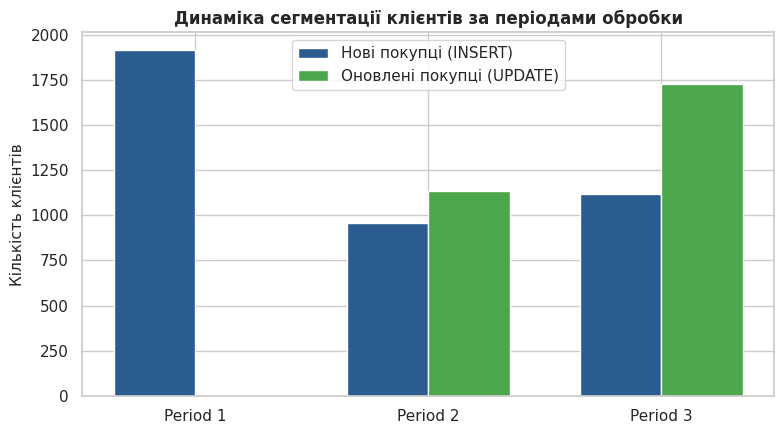

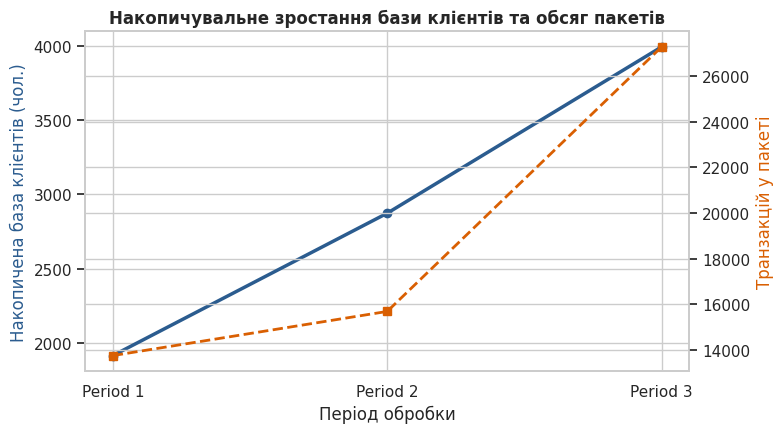

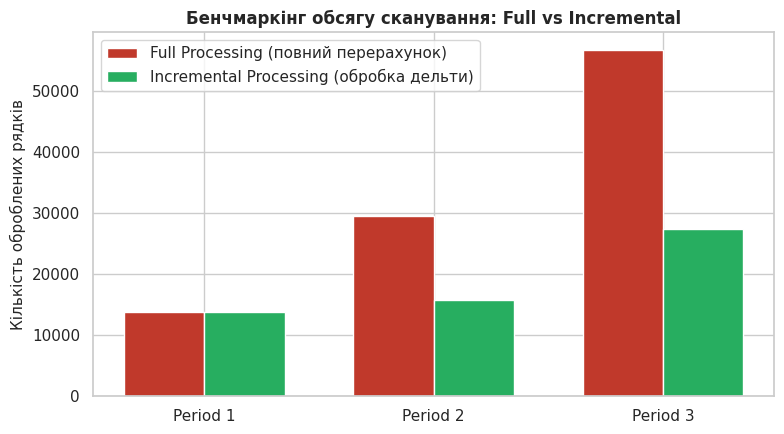

In [8]:
print("ПІДСУМКОВА ТАБЛИЦЯ ДИНАМІКИ ОБРОБКИ:")
display(summary_df)

# Графік 1: Сегментація клієнтів
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(summary_df))
width = 0.35
ax.bar(x - width/2, summary_df["Нових покупців"], width, label="Нові покупці (INSERT)", color="#2b5c8f")
ax.bar(x + width/2, summary_df["Оновлено покупців"], width, label="Оновлені покупці (UPDATE)", color="#4ca64c")
ax.set_ylabel("Кількість клієнтів", fontsize=11)
ax.set_title("Динаміка сегментації клієнтів за періодами обробки", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(summary_df["Період"])
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

# Графік 2: Накопичена база клієнтів
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.set_xlabel("Період обробки")
ax1.set_ylabel("Накопичена база клієнтів (чол.)", color="#2b5c8f")
ax1.plot(summary_df["Період"], summary_df["Покупців після обробки"], marker="o", color="#2b5c8f", linewidth=2.5)
ax2 = ax1.twinx()
ax2.set_ylabel("Транзакцій у пакеті", color="#d95f02")
ax2.plot(summary_df["Період"], summary_df["Транзакцій"], marker="s", color="#d95f02", linewidth=2, linestyle="--")
plt.title("Накопичувальне зростання бази клієнтів та обсяг пакетів", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Графік 3: Бенчмаркінг сканування
t1 = summary_df.loc[0, "Транзакцій"]
t2 = summary_df.loc[1, "Транзакцій"]
t3 = summary_df.loc[2, "Транзакцій"]
full_scans = [t1, t1 + t2, t1 + t2 + t3]
inc_scans = [t1, t2, t3]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width/2, full_scans, width, label="Full Processing (повний перерахунок)", color="#c0392b")
ax.bar(x + width/2, inc_scans, width, label="Incremental Processing (обробка дельти)", color="#27ae60")
ax.set_ylabel("Кількість оброблених рядків", fontsize=11)
ax.set_title("Бенчмаркінг обсягу сканування: Full vs Incremental", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(summary_df["Період"])
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## 9. Висновки

### Порівняння Full Processing та Incremental Processing:
1. **Full Processing (Повна обробка):** при кожному надходженні нового пакета транзакцій система зчитує весь історичний масив даних з початку часів та перераховує агреговані метрики для всіх клієнтів заново.
   - Сумарний обсяг сканування за 3 пакети: $13\,752 + 29\,440 + 56\,726 = 99\,918$ транзакцій.
   - Часова та обчислювальна складність: $O(N^2)$ при повторюваних періодах.
2. **Incremental Processing (Інкрементальна обробка):** система обробляє виключно дельту $\Delta N$ (новий пакет), локально розраховує зміни та оновлює стан за допомогою точкових операцій `INSERT` (для нових клієнтів) та `UPDATE` (для активних клієнтів).
   - Сумарний обсяг сканування: $13\,752 + 15\,688 + 27\,286 = 56\,726$ транзакцій.
   - Економія обчислювальних ресурсів склала **43.2%** уже на трьох періодах!

### Відповідь на контрольне запитання:
**Чому при надходженні нових даних доцільніше обробляти тільки новий фрагмент, а не повторно весь накопичений набір даних?**
- **Пропускна здатність I/O та пам'ять:** при інкрементальній обробці мінімізується дискове читання/запис та споживання оперативної пам'яті, що є головним вузьким місцем (bottleneck) у сучасних Big Data системах.
- **Масштабованість (Scalability):** у промислових сховищах даних (DWH, Data Lakehouse) із мільярдами подій повний щоденний перерахунок технічно неможливий (window of ingestion). Інкрементальний підхід забезпечує лінійну складність $O(N)$ замість катастрофічної квадратичної.
- **Швидкість (Low Latency / Near Real-Time):** інкрементальний конвеєр дозволяє бізнесу отримувати актуальні метрики за лічені секунди після надходження транзакцій, без очікування багатогодинних пакетних розрахунків.
- **Консистентність та надійність:** як доведено верифікацією, інкрементальне агрегування дає 100% математично точний результат, ідентичний повній обробці.